In [2]:
import sys, os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from Data.df_json import df

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import chi2_contingency   # uv add seaborn matplotlib scipy

In [48]:
#df = df.rename(columns= {"sub-departament" : "SubDepartament"})
df.columns

Index(['first_name', 'last_name', 'linkedin_url', 'title', 'email_status',
       'email', 'state_user', 'city_user', 'country_user', 'seniority',
       'company', 'company_year', 'industry', 'num_employeers', 'city_company',
       'state_company', 'country_company', 'job_title', 'job_date',
       'departament', 'sub-departament', 'function', 'linkedin_url_norm',
       'Date', 'Fuente', 'Producto', 'Respuesta', 'Respuesta_canal', 'Stage',
       'Contacto_canal', 'Data_momentum', 'respondio', 'anio_fundacion',
       'antiguedad_empresa', 'antiguedad_cargo', 'tamano', 'Lead',
       'seniority_group', 'department_group', 'function_group'],
      dtype='str')

In [61]:
for c in ["Date", "job_date"]:
    df[c] = pd.to_datetime(df[c], unit="ms", utc=True, errors="coerce")

df["respondio"] = df["Respuesta"].eq("Si")
df["anio_fundacion"] = df["company_year"].astype("Int64")
df["antiguedad_empresa"] = df["Date"].dt.year - df["anio_fundacion"]
df["antiguedad_cargo"] = (df["Date"] - df["job_date"]).dt.days / 365
df["tamano"] = pd.cut(df["num_employeers"], [0, 10, 50, 200, 1000, np.inf],
                      labels=["1-10", "11-50", "51-200", "201-1000", "1000+"])

df["respuesta_int"] = df["respondio"].astype(int)
df["Lead"] = df["Stage"].isin(["Lead", "Prospecto", "Piloto", "Propuesta", "Meet", "Deel", "lost"]).astype(int)

In [ ]:
condiciones = [
   df['state'].isin(['none', 'not_interested', 'replied']),
   df['state'].isin(['interested']),
   df['state'].isin(['later_interested']),
]
resultados = ['Contactado', 'Lead', 'Prospecto']

df['Stage'] = np.select(condiciones, resultados, default='Sin clasificar')

In [24]:
df.Producto.unique()

<StringArray>
[           nan,           'TA',          'SOU',           'CM',
        'PS-CM',        'TA-CM', 'SIN_PRODUCTO',        'PS-TA',
           'PS',     'PS-TA-CM']
Length: 10, dtype: str

(0.0, 1301.44)

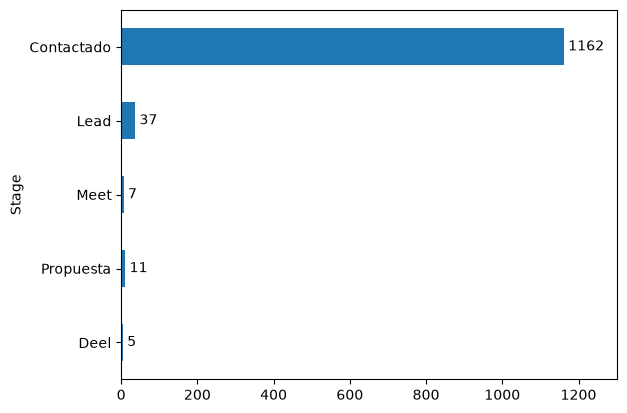

In [ ]:
#ORDEN_STAGE_TOTAL = ["Contactado", "Piloto", "not_interested", "Prospecto" , "lost" ,"Lead", "Meet", "Propuesta", "Deel"]  
ORDEN_STAGE = ["Contactado", "Lead", "Meet", "Propuesta", "Deel"]  # ajusta a tus valores

#df['Stage'].value_counts().reindex(ORDEN_STAGE).plot.barh().invert_yaxis()
conteo = df["Stage"].value_counts().reindex(ORDEN_STAGE)


ax = conteo.plot.barh()
ax.invert_yaxis()
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlim(0, conteo.max() * 1.12)

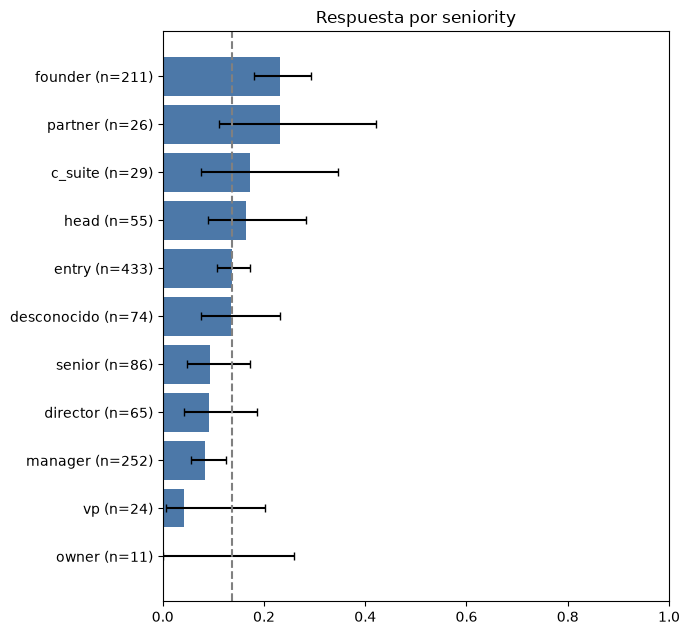

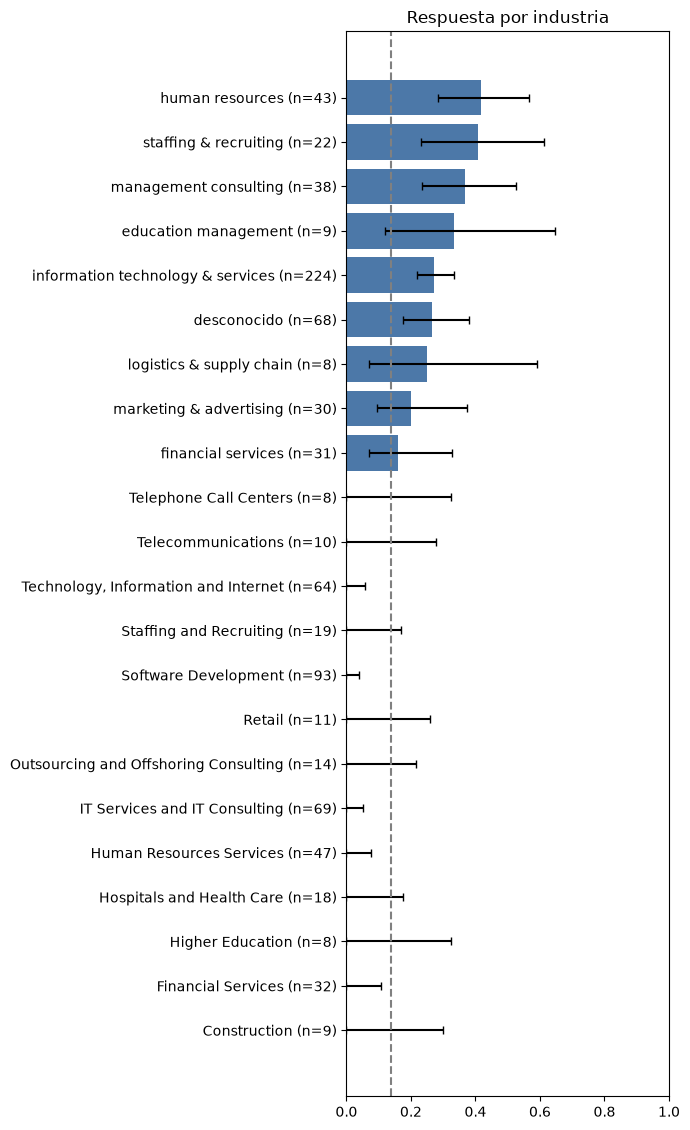

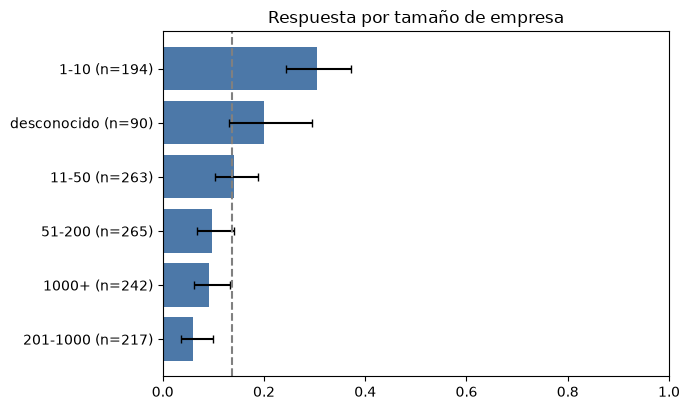

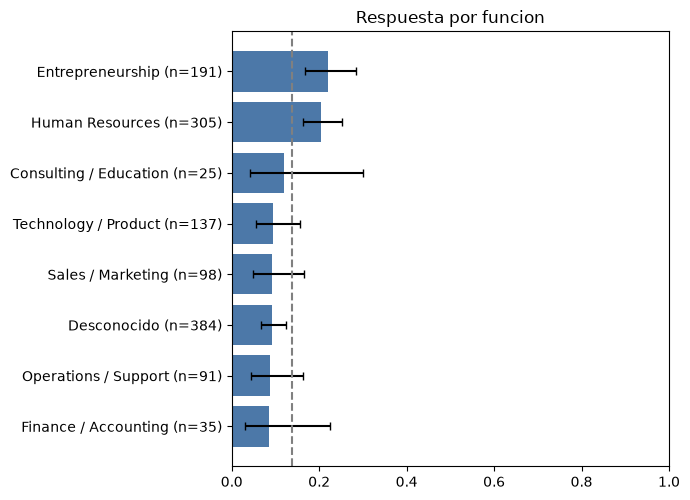

In [69]:
def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    lo = min(max(c - h, 0.0), p)   # no baja de 0 y nunca queda por encima de p
    hi = max(min(c + h, 1.0), p)   # no pasa de 1 y nunca queda por debajo de p
    return lo, hi

def tasa_por_categoria(df, col, y="respondio", min_n=8):
    g = df.groupby(col, observed=True, dropna=False)[y].agg(n="size", k="sum").reset_index()
    g[col] = g[col].astype("object").fillna("desconocido")
    g["tasa"] = g["k"] / g["n"]
    g[["lo", "hi"]] = [wilson(k, n) for k, n in zip(g["k"], g["n"])]
    return g[g["n"] >= min_n].sort_values("tasa")

def graficar_tasa(df, col, titulo, y="respondio"):
    t = tasa_por_categoria(df, col, y)
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(t) + 1.5))
    pos = np.arange(len(t))
    ax.barh(pos, t["tasa"], xerr=[t["tasa"] - t["lo"], t["hi"] - t["tasa"]],
            color="#4C78A8", capsize=3)
    ax.set_yticks(pos, [f"{c} (n={n})" for c, n in zip(t[col], t["n"])])
    ax.axvline(df[y].mean(), ls="--", color="gray")   # tasa global
    ax.set_xlim(0, 1); ax.set_title(titulo)
    plt.tight_layout()

graficar_tasa(df, "seniority", "Respuesta por seniority")
graficar_tasa(df, "industry", "Respuesta por industria")
graficar_tasa(df, "tamano", "Respuesta por tamaño de empresa")
graficar_tasa(df, "function_group", "Respuesta por funcion")

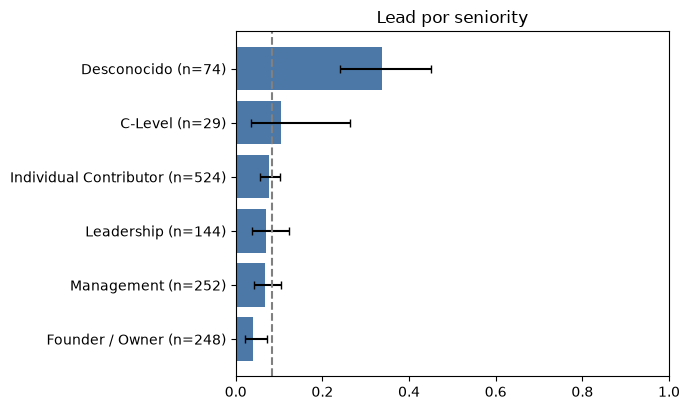

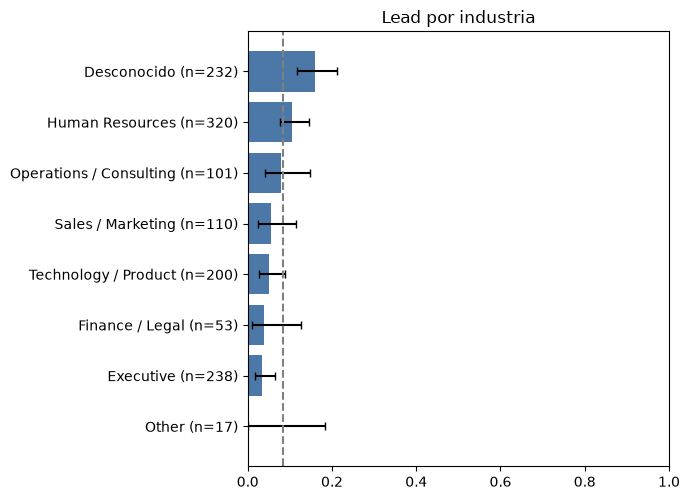

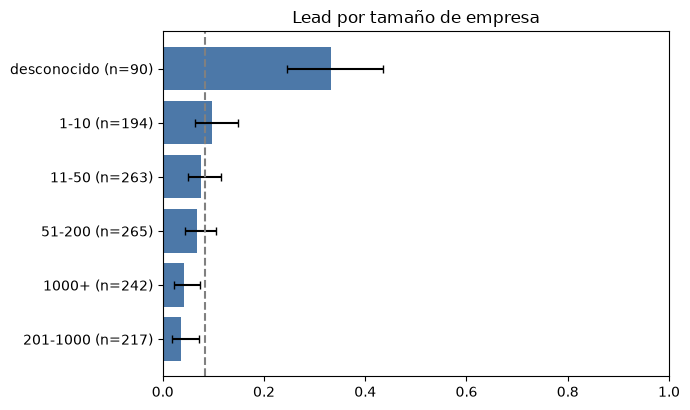

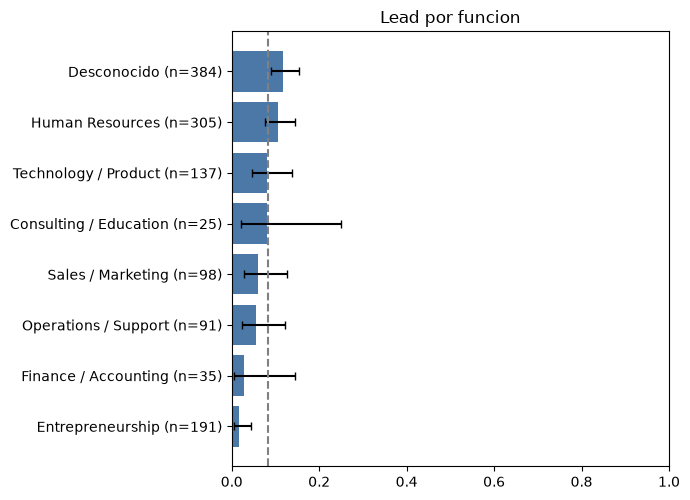

In [50]:
def tasa_por_categoria(df, col, y="Lead", min_n=8):
    g = df.groupby(col, observed=True, dropna=False)[y].agg(n="size", k="sum").reset_index()
    g[col] = g[col].astype("object").fillna("desconocido")
    g["tasa"] = g["k"] / g["n"]
    g[["lo", "hi"]] = [wilson(k, n) for k, n in zip(g["k"], g["n"])]
    return g[g["n"] >= min_n].sort_values("tasa")

def graficar_tasa(df, col, titulo, y="Lead"):
    t = tasa_por_categoria(df, col, y)
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(t) + 1.5))
    pos = np.arange(len(t))
    ax.barh(pos, t["tasa"], xerr=[t["tasa"] - t["lo"], t["hi"] - t["tasa"]],
            color="#4C78A8", capsize=3)
    ax.set_yticks(pos, [f"{c} (n={n})" for c, n in zip(t[col], t["n"])])
    ax.axvline(df[y].mean(), ls="--", color="gray")   # tasa global
    ax.set_xlim(0, 1); ax.set_title(titulo)
    plt.tight_layout()


graficar_tasa(df, "seniority_group", "Lead por seniority")
graficar_tasa(df, "department_group", "Lead por industria")
graficar_tasa(df, "tamano", "Lead por tamaño de empresa")
graficar_tasa(df, "function_group", "Lead por funcion")

<Axes: xlabel='Fuente', ylabel='Contacto_canal'>

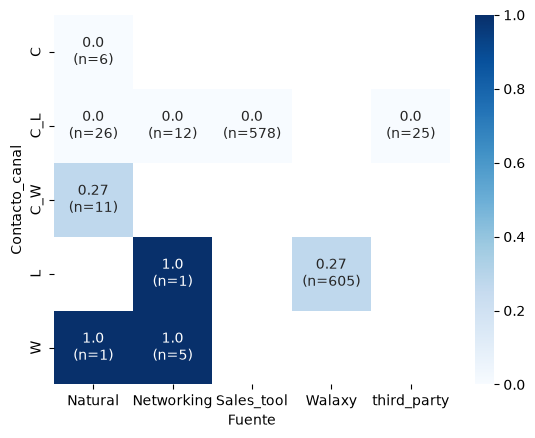

In [30]:
piv = df.pivot_table(index="Contacto_canal", columns="Fuente", values="respondio", aggfunc="mean")
cnt = df.pivot_table(index="Contacto_canal", columns="Fuente", values="respondio", aggfunc="size")
anot = piv.round(2).astype(str) + "\n(n=" + cnt.fillna(0).astype(int).astype(str) + ")"
sns.heatmap(piv, annot=anot, fmt="", cmap="Blues", vmin=0)

In [25]:
def asociacion_respuesta(df, cols, y="respondio", min_n=8):
    filas = []
    for c in cols:
        x = df[c].astype("object").fillna("desconocido")
        x = x.where(x.map(x.value_counts()) >= min_n, "otros")   # agrupa categorías raras
        t = pd.crosstab(x, df[y])
        if t.shape[0] < 2 or t.shape[1] < 2:
            continue
        chi2, p, _, esp = chi2_contingency(t)
        v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
        filas.append({"variable": c, "categorias": t.shape[0], "cramers_v": v,
                      "p_value": p, "celdas_esperadas<5": (esp < 5).mean()})
    return pd.DataFrame(filas).sort_values("cramers_v", ascending=False)



In [26]:
def asociacion_lead(df, cols, y="Lead", min_n=8):
    filas = []
    for c in cols:
        x = df[c].astype("object").fillna("desconocido")
        x = x.where(x.map(x.value_counts()) >= min_n, "otros")   # agrupa categorías raras
        t = pd.crosstab(x, df[y])
        if t.shape[0] < 2 or t.shape[1] < 2:
            continue
        chi2, p, _, esp = chi2_contingency(t)
        v = np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
        filas.append({"variable": c, "categorias": t.shape[0], "cramers_v": v,
                      "p_value": p, "celdas_esperadas<5": (esp < 5).mean()})
    return pd.DataFrame(filas).sort_values("cramers_v", ascending=False)


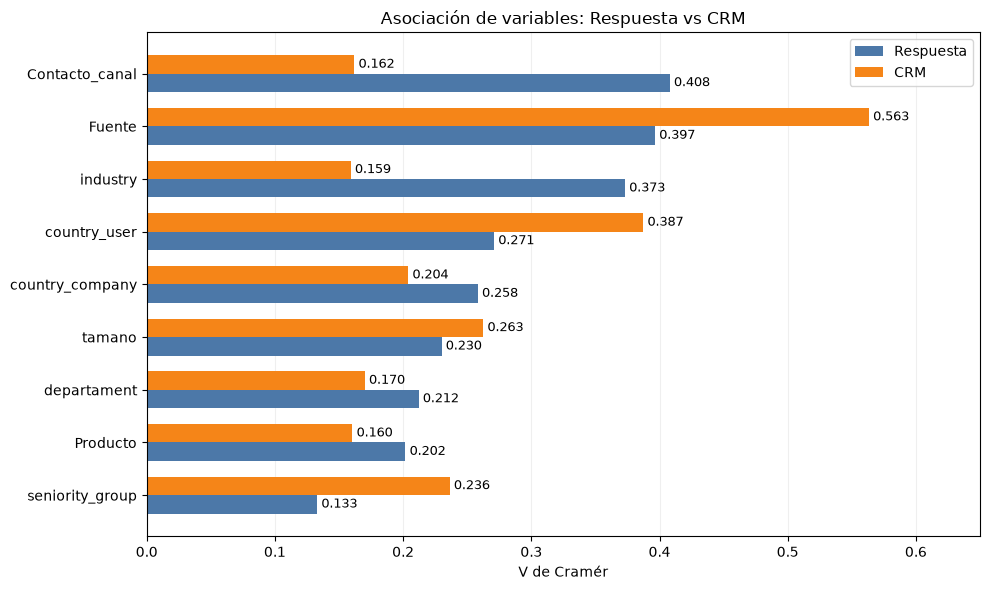

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



cramer_respuesta = asociacion_respuesta(df, ["seniority_group", "industry", "tamano", "country_company", "country_user",
                "Producto", "Fuente", "Contacto_canal", "departament"])

cramer_crm = asociacion_lead(df, ["seniority_group", "industry", "tamano", "country_company", "country_user",
                "Producto", "Fuente", "Contacto_canal", "departament"])
# Unir las dos tablas por variable
comparacion = cramer_respuesta[
    ["variable", "cramers_v"]
].merge(
    cramer_crm[["variable", "cramers_v"]],
    on="variable",
    suffixes=("_respuesta", "_crm")
)

# Ordenar según asociación con respuesta
comparacion = comparacion.sort_values(
    "cramers_v_respuesta",
    ascending=True
)

# Posiciones para las barras
y = np.arange(len(comparacion))
alto = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Barras para respuesta
ax.barh(
    y - alto / 2,
    comparacion["cramers_v_respuesta"],
    height=alto,
    label="Respuesta",
    color="#4C78A8"
)

# Barras para CRM
ax.barh(
    y + alto / 2,
    comparacion["cramers_v_crm"],
    height=alto,
    label="CRM",
    color="#F58518"
)

for contenedor in ax.containers:
    ax.bar_label(
        contenedor,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

# Etiquetas y formato
ax.set_yticks(y)
ax.set_yticklabels(comparacion["variable"])

ax.set_xlabel("V de Cramér")
ax.set_title("Asociación de variables: Respuesta vs CRM")
ax.set_xlim(0, 0.65)

ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:
#Index(['first_name', 'last_name', 'linkedin_url', 'title', 'email_status',
#       'email', 'state_user', 'city_user', 'country_user', 'seniority',
#       'company', 'company_year', 'industry', 'num_employeers', 'city_company',
#       'state_company', 'country_company', 'job_title', 'job_date',
#       'departament', 'SubDepartament', 'function', 'linkedin_url_norm',
#       'Date', 'Fuente', 'Producto', 'Respuesta', 'Respuesta_canal', 'Stage',
#       'Contacto_canal', 'Data_momentum'],
#      dtype='str')

In [35]:
variables = df.title.unique().tolist()

In [52]:
for col in [ "industry"]:
    print(f"\n{'='*15} {col.upper()} {'='*15}")
    print(df[col].value_counts(dropna=False).to_string())


=============== INDUSTRY ===============
industry
information technology & services                          224
Software Development                                        93
IT Services and IT Consulting                               69
NaN                                                         68
Technology, Information and Internet                        64
Human Resources Services                                    47
human resources                                             43
management consulting                                       38
Financial Services                                          32
financial services                                          31
marketing & advertising                                     30
staffing & recruiting                                       22
Staffing and Recruiting                                     19
Hospitals and Health Care                                   18
Outsourcing and Offshoring Consulting                       14
Reta

In [41]:
condiciones = [
    df["seniority"].isin(["founder", "owner", "partner"]),

    df["seniority"].isin(["c_suite"]),

    df["seniority"].isin(["director", "head", "vp"]),

    df["seniority"].isin(["manager"]),

    df["seniority"].isin(["entry", "senior", "intern"])
]

resultados = [
    "Founder / Owner",
    "C-Level",
    "Leadership",
    "Management",
    "Individual Contributor"
]

df["seniority_group"] = np.select(
    condiciones,
    resultados,
    default="Sin clasificar"
)

df.loc[
    df["seniority"].isna(),
    "seniority_group"
] = "Desconocido"

In [43]:
condiciones = [
    df["departament"].isin([
        "master_human_resources"
    ]),

    df["departament"].isin([
        "c_suite"
    ]),

    df["departament"].isin([
        "master_engineering_technical",
        "master_information_technology",
        "product_management",
        "design"
    ]),

    df["departament"].isin([
        "master_operations",
        "consulting"
    ]),

    df["departament"].isin([
        "master_sales",
        "master_marketing"
    ]),

    df["departament"].isin([
        "master_finance",
        "master_legal"
    ]),

    df["departament"].isin([
        "education",
        "medical_health"
    ])
]

resultados = [
    "Human Resources",
    "Executive",
    "Technology / Product",
    "Operations / Consulting",
    "Sales / Marketing",
    "Finance / Legal",
    "Other"
]

df["department_group"] = np.select(
    condiciones,
    resultados,
    default="Sin clasificar"
)

df.loc[
    df["departament"].isna(),
    "department_group"
] = "Desconocido"

In [45]:
condiciones = [
    df["function"].isin(["human_resources"]),

    df["function"].isin(["entrepreneurship"]),

    df["function"].isin([
        "engineering",
        "information_technology",
        "product_management",
        "data_science",
        "arts_and_design"
    ]),

    df["function"].isin([
        "operations",
        "support",
        "administrative"
    ]),

    df["function"].isin([
        "sales",
        "business_development",
        "marketing",
        "media_and_commmunication"
    ]),

    df["function"].isin([
        "finance",
        "accounting"
    ]),

    df["function"].isin([
        "consulting",
        "education"
    ])
]

resultados = [
    "Human Resources",
    "Entrepreneurship",
    "Technology / Product",
    "Operations / Support",
    "Sales / Marketing",
    "Finance / Accounting",
    "Consulting / Education"
]

df["function_group"] = np.select(
    condiciones,
    resultados,
    default="Sin clasificar"
)

df.loc[
    df["function"].isna(),
    "function_group"
] = "Desconocido"

In [ ]:
import pandas as pd
import statsmodels.formula.api as smf

# Seleccionar las variables
#datos = df[
#    ["function_group", "respuesta_int"]
#].dropna().copy()

# Ajustar modelo logístico
#modelo = smf.logit(
#    formula=(
#        'respuesta_int ~ C(function_group, '
#        'Treatment(reference="Human Resources"))'
#    ),
#    data=datos
#).fit()

#print(modelo.summary())

Optimization terminated successfully.
         Current function value: 0.367461
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          respuesta_int   No. Observations:                 1181
Model:                          Logit   Df Residuals:                     1176
Method:                           MLE   Df Model:                            4
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                 0.06244
Time:                        19:29:22   Log-Likelihood:                -433.97
converged:                       True   LL-Null:                       -462.87
Covariance Type:            nonrobust   LLR p-value:                 8.381e-12
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                -0.8277      0.156     -5.304      0.000      -1.134      -0.